# Example: Analysis of a Strangle Position in AMD
In this example, we analyze a strangle on Advanced Micro Devices, Inc. (AMD) using historical options data. A long (short) strangle buys (sells) a put at strike $K_{1}$ and a call at a higher strike $K_{2}$, with the same expiration date. If we set $K_{1}=K_{2}$, the strangle becomes a straddle.

We sell a strangle on AMD before its earnings release, so we make money if the share price stays between the two breakevens.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Construct profit diagrams for strangle positions:__ Build profit and loss profiles for long and short strangles by combining a put at $K_{1}$ and a call at $K_{2}\geq K_{1}$ with the same expiration date, and compute breakeven points where the position transitions from profit to loss.
> * __Calculate the probability of profit and the probability of exercise for a strangle:__ Use cumulative distribution functions of projected share price distributions to determine the likelihood that a strangle will be profitable at expiration, accounting for the two breakeven boundaries, and each leg's probability of exercise, under our belief $\mathbb{P}$ and the risk-neutral probabilities $\mathbb{Q}$.
> * __Evaluate the strangle after the earnings release:__ Buy both legs back at their premiums after the release and compute the profit or loss, which includes the extrinsic value still left in the legs.

Let's get started!
___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, etc. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/). 

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

### Data
To start, load the options data using [the `MyOptionsChainDataSet(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/data/#VLQuantitativeFinancePackage.MyOptionsChainDataSet) and store the metadata in the `metadata::Dict{String,Any}` variable and the options chain data in the `optionschain::DataFrame` variable.

In [2]:
metadata, optionschain = let

    # initialize: load AMD's options chain for the quote date from the course archive -
    options_dataset = MyOptionsChainDataSet(ticker="amd-2026"); # the chain and its metadata
    metadata = options_dataset.metadata; # Dict: quote date, expiration date, share price, DTE, ATM IV, ...
    optionschain = options_dataset.data; # DataFrame: one row per contract (strike, type, bid, ask, mid, IV, Greeks)

    # return -
    (metadata, optionschain)
end;

What's in the `metadata::Dict{String,Any}` dictionary?

In [3]:
metadata |> keys # which fields does the metadata dictionary hold?

KeySet for a Dict{String, Any} with 10 entries. Keys:
  "DTE"
  "purchase_date"
  "historical_volatility"
  "underlying_share_price_ask"
  "source"
  "underlying_share_price_bid"
  "is_weekly"
  "atm_IV"
  "expiration_date"
  "underlying_share_price_mid"

What about the `optionschain::DataFrame` variable?

In [4]:
optionschain # one row per contract on the quote date

Row,Strike,Moneyness,Bid,Mid,Ask,Last,Volume,Open Int,IV,Delta,Type
,Float64,Float64,Float64,Float64,Float64,Float64,Int64,String7,Float64,Float64,String7
1,5.0,0.9906,524.2,526.53,528.85,517.3,0,"1,074",5.2163,0.9996,Call
2,10.0,0.9812,518.9,521.4,523.9,479.51,0,4,3.7202,0.9998,Call
3,15.0,0.9718,514.3,516.63,518.95,0.0,0,0,3.8539,0.9992,Call
4,20.0,0.9624,509.3,511.63,513.95,466.97,0,956,3.4532,0.9992,Call
5,25.0,0.953,504.1,506.55,509.0,427.94,0,212,2.9877,0.9994,Call
6,30.0,0.9436,499.6,501.83,504.05,457.14,0,208,3.167,0.9986,Call
7,35.0,0.9342,494.65,496.85,499.05,479.33,0,9,2.9794,0.9985,Call
8,40.0,0.9247,488.4,491.17,493.95,483.4,1,13,1.9981,0.9999,Call
9,45.0,0.9153,484.25,486.7,489.15,425.63,0,101,2.4434,0.9991,Call


### Constants
Next, let's set the constants. See the comments next to the constants for definitions, units, permissible values, etc. 

In [5]:
# the share price and the time to expiration -
Sₒ = metadata["underlying_share_price_mid"] |> x-> parse(Float64, x); # close on the quote date, 2026-10-26 (USD/share)
Δt = (1/365); # one calendar day, expressed in years
DTE = metadata["DTE"] |> x-> parse(Float64, x); # days to expiration (days)
T = DTE*Δt; # time to expiration (years)

# the risk-free rate, from the 13-week Treasury bill -
τ_bill = 91/365; # term of the 13-week Treasury bill (years)
y_bill = 0.0415; # 13-week bill coupon-equivalent yield on 2026-10-26, U.S. Treasury Daily Treasury Bill Rates; update it if you change the quote date
# https://home.treasury.gov/resource-center/data-chart-center/interest-rates/TextView?type=daily_treasury_bill_rates&field_tdr_date_value_month=202610
gᵧ = log(1 + y_bill*τ_bill)/τ_bill; # continuously compounded risk-free rate (1/yr)
𝒟 = exp(gᵧ*T); # accumulation factor from today to expiration (dimensionless)

# the strangle: a put at K₁ and a call at K₂ ≥ K₁ (set K₁ = K₂ for a straddle) -
K₁ = 470.0; # strike price of the put leg (USD/share)
K₂ = 630.0; # strike price of the call leg (USD/share)
θ = -1; # orientation: 1 = long (we buy both legs), -1 = short (we sell both legs)
position = (K₁ == K₂) ? "straddle" : "strangle"; # name of the position, used in tables and labels

# show the setup -
println("Sₒ = $(Sₒ) USD/share, DTE = $(DTE) days, put at K₁ = $(K₁) and call at K₂ = $(K₂) USD/share, θ = $(θ) ($(θ == -1 ? "short" : "long") $(position))");

# checks -
@assert K₁ ≤ K₂ "the put strike K₁ must not be above the call strike K₂"

Sₒ = 531.26 USD/share, DTE = 53.0 days, put at K₁ = 470.0 and call at K₂ = 630.0 USD/share, θ = -1 (short strangle)


In this example, we'll need to do a projection of the future share price distribution at the contract's expiration date. We'll use a Geometric Brownian Motion (GBM) model to project the future share price distribution at expiration.

Let's load the single asset geometric Brownian motion (SAGBM) parameters which we estimated a few lectures ago, which include the drift and diffusion coefficients for each ticker. We'll store this data in the `parameters_df::DataFrame` variable:

In [6]:
parameters_df = let

    # load the GBM parameters estimated from the 2014 to 2024 training data, one row per ticker -
    df = CSV.read(joinpath(_PATH_TO_DATA,"SAGBM-Parameters-Fall-2025.csv"), DataFrame);

    # return -
    df
end;

We are looking at `AMD`, so let's see what the parameters for this ticker are:

In [7]:
filter(:ticker=> x-> x=="AMD", parameters_df) # AMD's row: drift (mean growth rate) and volatility

Row,ticker,drift,t,lower_bound_drift,upper_bound_drift,volatility
,String7,Float64,Float64,Float64,Float64,Float64
1,AMD,0.439658,1.96082,0.43459,0.444725,0.474283


### Contract models
Next, we construct contract models for the options in this example. We begin by building an instance of the [MyAmericanCallContractModel type](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.MyAmericanCallContractModel) using the [custom build(...) method](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.build-Tuple{Type{MyAmericanCallContractModel},%20NamedTuple}). 

The [build(...) method](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.build-Tuple{Type{MyAmericanCallContractModel},%20NamedTuple}) takes two arguments: the type to build, and a [NamedTuple](https://docs.julialang.org/en/v1/base/base/#Core.NamedTuple) containing the strike price `K`, the `premium` paid for the option, the days to expiration `DTE` (units: years), the `sense` parameter for position direction, the number of contracts in the `copy` field and the implied volatility in the `IV` field.

We save the call option contract model in the `call_option_model::MyAmericanCallContractModel` variable:

In [8]:
call_option_model = let

    # initialize: the call at strike K₂ on the quote date -
    call_row = filter([:Strike,:Type] => (x,y) -> (x == K₂ && y == "Call"), optionschain); # the call row at K₂
    premium = call_row[1,:Mid]; # premium: the midpoint of the bid and the ask (USD/share)
    IV = call_row[1,:IV]; # implied volatility of this contract (decimal)

    # build the contract model -
    model = build(MyAmericanCallContractModel, (
        K = K₂, # strike price (USD/share)
        premium = premium, # premium paid (long) or received (short) (USD/share)
        DTE = T, # time to expiration (years)
        sense = θ, # orientation: 1 = long (bought), -1 = short (sold)
        copy = 1, # number of contracts
        IV = IV # implied volatility (decimal)
    ));

    # checks: the chain has exactly one call at K₂ -
    @assert nrow(call_row) == 1 "expected one call at K₂ = $(K₂) in the chain"

    # return -
    model
end

MyAmericanCallContractModel(630.0, -1, 0.1452054794520548, 0.5569, 15.3, nothing, 1)

The put contract, which is an instance of the [MyAmericanPutContractModel type](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.MyAmericanPutContractModel), is constructed in a similar way to the call option. We save the put option contract model in the `put_option_model::MyAmericanPutContractModel` variable:

In [9]:
put_option_model = let

    # initialize: the put at strike K₁ on the quote date -
    put_row = filter([:Strike,:Type] => (x,y) -> (x == K₁ && y == "Put"), optionschain); # the put row at K₁
    premium = put_row[1,:Mid]; # premium: the midpoint of the bid and the ask (USD/share)
    IV = put_row[1,:IV]; # implied volatility of this contract (decimal)

    # build the contract model -
    model = build(MyAmericanPutContractModel, (
        K = K₁, # strike price (USD/share)
        premium = premium, # premium paid (long) or received (short) (USD/share)
        DTE = T, # time to expiration (years)
        sense = θ, # orientation: 1 = long (bought), -1 = short (sold)
        copy = 1, # number of contracts
        IV = IV # implied volatility (decimal)
    ));

    # checks: the chain has exactly one put at K₁ -
    @assert nrow(put_row) == 1 "expected one put at K₁ = $(K₁) in the chain"

    # return -
    model
end

MyAmericanPutContractModel(470.0, -1, 0.1452054794520548, 0.5755, 18.9, nothing, 1)

___

## Task 1: Compute Profit, Loss and Breakeven Points
In this task, we compute the profit and loss (P&L) profile of our short strangle at expiration, as well as its breakeven points. 

A [strangle](https://www.fidelity.com/learning-center/investment-products/options/options-strategy-guide/short-strangle) buys (or sells) a put at strike $K_{1}$ and a call at strike $K_{2}$, with the _same expiration_ and $K_{1}<S(0)<K_{2}$. A [straddle](https://www.fidelity.com/learning-center/investment-products/options/options-strategy-guide/short-straddle) uses one strike, $K_{1}=K_{2}\approx{S(0)}$.

> __Long (short) strangle__
> 
> For a long strangle, we buy both legs ($\theta = 1$). For a short strangle, we sell both legs ($\theta = -1$). We set the strikes $K_{1}$ and $K_{2}$ and the orientation $\theta$ in the constants cell above, which prints them along with the share price $S(0)$ and the days to expiration.
>
> In this example, we sell both legs ($\theta = -1$).

### Profit and Breakeven Analysis
Let $\mathcal{P}_{p}$ and $\mathcal{P}_{c}$ denote the premiums of the put and the call (USD/share), and let $\mathcal{D}_{T,0}(g_{y})$ be the accumulation factor from today to expiration. The premiums are paid today and the payoffs arrive at expiration, so the profit of a single strangle at expiration $\hat{P}_{\mathcal{C}}$ compares the payoffs with the premiums grown to expiration:

$$\hat{P}_{\mathcal{C}} = \theta\cdot\Bigl[(K_{1}-S(T))^{+}+(S(T)-K_{2})^{+}-\mathcal{D}_{T,0}(g_{y})\cdot(\mathcal{P}_{p}+\mathcal{P}_{c})\Bigr]$$

where $\theta=-1$ if both legs are sold (short) and $\theta=1$ if both are bought (long). Here $V_{p}(K_{1},S(T)) = (K_{1}-S(T))^{+}=\max(K_{1}-S(T),0)$ is the payoff function for the put contract, and $V_{c}(K_{2},S(T)) = (S(T)-K_{2})^{+} = \max(S(T)-K_{2},0)$ is the payoff function for the call contract. The profit (or loss) of a strangle has three regimes given by:

$$
\hat{P}_{\mathcal{C}} = \begin{cases}
  \theta\cdot\Bigl[(S(T)-K_{2})-\mathcal{D}_{T,0}(g_{y})\cdot\left(\mathcal{P}_{p}+\mathcal{P}_{c}\right)\Bigr]  & S(T)>K_{2} \\
  -\theta\cdot\mathcal{D}_{T,0}(g_{y})\cdot\left(\mathcal{P}_{p}+\mathcal{P}_{c}\right) & K_{1}\leq S(T)\leq K_{2} \\
    \theta\cdot\Bigl[(K_{1}-S(T))-\mathcal{D}_{T,0}(g_{y})\cdot\left(\mathcal{P}_{p}+\mathcal{P}_{c}\right)\Bigr] & S(T)<K_{1}
\end{cases}
$$

Finally, a strangle has _two_ possible breakeven points denoted as $S^{\ddagger}_{-}$ and $S^{\ddagger}_{+}$:
* If $S(T)>K_{2}$: a strangle will breakeven at $S^{\ddagger}_{+} = K_{2} + \mathcal{D}_{T,0}(g_{y})\cdot\left(\mathcal{P}_{p}+\mathcal{P}_{c}\right)$
* If $S(T)<K_{1}$: a strangle will breakeven at $S^{\ddagger}_{-} = K_{1} - \mathcal{D}_{T,0}(g_{y})\cdot\left(\mathcal{P}_{p}+\mathcal{P}_{c}\right)$.

With $K_{1}=K_{2}=K$, these are the profit and breakevens of a straddle. A short strangle profits when the share price finishes between the breakevens, and a long strangle when it finishes outside them.

So what do we see?

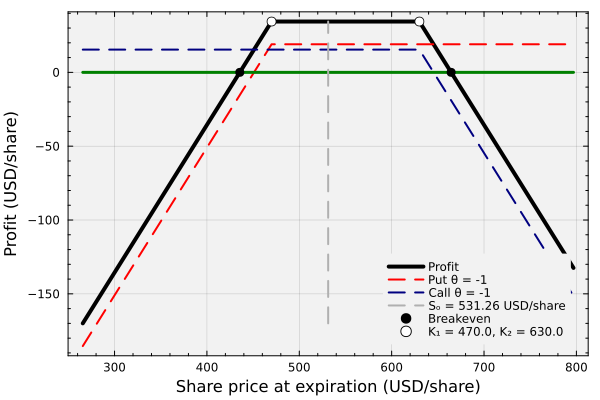

In [10]:
let

    # initialize -
    δ = 0.50; # plot S(T) from (1 - δ)⋅Sₒ to (1 + δ)⋅Sₒ
    S = range((1-δ)*Sₒ, stop = (1+δ)*Sₒ, step = 0.1) |> collect; # share prices at expiration (USD/share)
    premiums = put_option_model.premium + call_option_model.premium; # 𝒫_p + 𝒫_c (USD/share)
    profit_between = -θ*𝒟*premiums; # profit for K₁ ≤ S(T) ≤ K₂ (USD/share)

    # compute: the columns are S(T), the put's profit, the call's profit, and the position's profit -
    profit_array = profit([put_option_model, call_option_model], S; 𝒟 = 𝒟); # premiums grown to expiration with 𝒟

    # the breakevens: column 1 is the share price S‡, column 2 the profit there (zero) -
    breakeven_array = zeros(2,2);
    breakeven_array[1,1] = K₂ + 𝒟*premiums; # upper breakeven S‡₊ (USD/share)
    breakeven_array[2,1] = K₁ - 𝒟*premiums; # lower breakeven S‡₋ (USD/share)

    # plot: the position's profit (black), each leg's profit (dashed), and the zero-profit line (green) -
    plot(profit_array[:,1], profit_array[:,4], lw=4, label="Profit", c=:black,
        bg="gray95", background_color_outside="white", framestyle = :box, fg_legend = :transparent)
    plot!(profit_array[:,1], profit_array[:,2], lw=2, label="Put θ = $(θ)", ls=:dash, c=:red)
    plot!(profit_array[:,1], profit_array[:,3], lw=2, label="Call θ = $(θ)", ls=:dash, c=:navyblue)
    plot!(S, zeros(length(S)), lw=3, c=:green, label="")

    # the share price on the quote date, Sₒ: a dashed vertical line across the profit range -
    number_of_steps = length(S);
    VLINE = zeros(number_of_steps, 2); # column 1 is x (always Sₒ), column 2 is y
    VLINE[:,1] .= Sₒ*ones(number_of_steps)
    VLINE[:,2] .= range(minimum(profit_array[:,end]), stop = maximum(profit_array[:,end]), length = number_of_steps) |> collect;
    plot!(VLINE[:,1], VLINE[:,2], lw=2, c= :gray69, ls=:dash, label="Sₒ = $(Sₒ) USD/share")

    # mark the two breakevens (black) and the profit at the strikes K₁ and K₂ (white) -
    scatter!(breakeven_array[:,1], breakeven_array[:,2], c=:black, label="Breakeven", ms=5, xminorticks=true, yminorticks=true)
    scatter!([K₁, K₂],[profit_between, profit_between], ms=5, label = "K₁ = $(K₁), K₂ = $(K₂)", msc=:black, mc=:white)

    # labels -
    xlabel!("Share price at expiration (USD/share)", fontsize=18)
    ylabel!("Profit (USD/share)", fontsize=18)
end

What are the breakeven points?

In [11]:
breakeven_array = let

    # initialize -
    premiums = put_option_model.premium + call_option_model.premium; # 𝒫_p + 𝒫_c (USD/share)

    # compute: the profit is zero where K₁ - S(T) or S(T) - K₂ equals the premiums grown to expiration -
    breakeven_array = zeros(2);
    breakeven_array[1] = K₂ + 𝒟*premiums; # upper breakeven S‡₊ (USD/share)
    breakeven_array[2] = K₁ - 𝒟*premiums; # lower breakeven S‡₋ (USD/share)

    # return -
    breakeven_array
end

2-element Vector{Float64}:
 664.405647088967
 435.594352911033

___

## Task 2: Compute the Probability of Profit (POP) and the Probability of Exercise (POE)
In this task, we compute the Probability of Profit (POP) of our short strangle and the Probability of Exercise (POE) of each leg at expiration.

To start, we simulate share prices at expiration under the risk-neutral probabilities $\mathbb{Q}$: geometric Brownian motion with drift $g_{y}$ and the at-the-money implied volatility. Later, we compare the probabilities with our belief $\mathbb{P}$, built from the SAGBM parameters we loaded earlier.

We'll save the GBM model in the `model::MyGeometricBrownianMotionEquityModel` variable:

In [12]:
model = let

    # initialize -
    ATM_IV = metadata["atm_IV"] |> x-> parse(Float64, x); # at-the-money implied volatility on the quote date (decimal)

    # build GBM under the risk-neutral probabilities ℚ: drift = risk-free rate, volatility = ATM implied volatility -
    model = build(MyGeometricBrownianMotionEquityModel, (
        μ = gᵧ, # drift (1/yr)
        σ = ATM_IV # volatility (1/sqrt(yr))
    ));

    # return -
    model
end

MyGeometricBrownianMotionEquityModel(0.04128677804517802, 0.5617)

Now that we have a populated [MyGeometricBrownianMotionEquityModel instance](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.MyGeometricBrownianMotionEquityModel) holding the `AMD` data, let's generate `number_of_samples` possible future share price values using the [sample(...) function exported by the VLQuantitativeFinancePackage.jl package](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.sample-Tuple{MyMultipleAssetGeometricBrownianMotionEquityModel,%20NamedTuple}).
* The [sample method](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.sample-Tuple{MyMultipleAssetGeometricBrownianMotionEquityModel,%20NamedTuple}) takes a `model::MyGeometricBrownianMotionEquityModel` instance as the first argument, along with the time values that we wish to sample: `T₁::Float64` is the start time, `T₂::Float64` is the stop time (in units of `years`), `Δt::Float64` is the time step (in units of `years`), and `Sₒ::Float64` denotes the initial share price (in units of `USD/share`). Finally, we pass in the number of samples we want to generate in the `number_of_paths` argument.
* The [sample method](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.sample-Tuple{MyMultipleAssetGeometricBrownianMotionEquityModel,%20NamedTuple}) generates `number_of_paths` sample paths from $T_{1}\rightarrow{T}_{2}$ in steps of $\Delta{t}$. However, we only want the share prices corresponding to the duration of the contract, i.e., $T_{2} = \text{DTE}$. Thus, we pass the full `samples` array [using the Julia pipe operator](https://docs.julialang.org/en/v1/manual/functions/#Function-composition-and-piping) to a slicing operation where we select columns `2:end` of the last row (col 1 holds the time). We store the `number_of_paths` samples of the share price at $T_{2}$ in the `endpoint_samples::Array{Float64,1}` variable.

So what do we get?

In [13]:
endpoint_samples = let

    # initialize -
    Random.seed!(5660); # fix the random numbers, so every run gives the same samples
    number_of_samples = 50000; # number of simulated share price paths

    # simulate daily GBM paths from today (T₁ = 0) to expiration (T₂ = T) -
    paths = VLQuantitativeFinancePackage.sample(model, (
        T₁ = 0.0, # start time (years)
        T₂ = T, # end time (years)
        Δt = Δt, # step size (years)
        Sₒ = Sₒ # initial share price (USD/share)
    ), number_of_paths = number_of_samples); # rows are days; column 1 is the time, columns 2:end are the paths
    endpoint = paths[end, 2:end]; # the last row: the share price at expiration on each path (USD/share)

    println("The mean projected price for GBM: $(mean(endpoint))");

    # return -
    endpoint
end;

The mean projected price for GBM: 534.7787839167826


#### Check: Are future GBM share prices log-normally distributed?
We expect geometric Brownian motion to generate __log-normally distributed__ share prices. We can check this expectation by performing an [exact one-sample Kolmogorov-Smirnov test](https://juliastats.org/HypothesisTests.jl/stable/nonparametric/#Kolmogorov-Smirnov-test) on the samples and the log-normal distribution that geometric Brownian motion predicts.
> __Hypothesis:__ The `H0:null hypothesis` for the test is the data (endpoint samples generated using geometric Brownian motion) comes from the LogNormal distribution `d_gbm`. The alternative hypothesis `H1:alternative` is the samples are not drawn from `d_gbm`.

Under geometric Brownian motion, $\ln S(T)$ is normal with mean $\ln S_{0}+(\mu-\sigma^{2}/2)T$ and standard deviation $\sigma\sqrt{T}$. Let's build this [LogNormal distribution exported by the Distributions.jl package](https://juliastats.org/Distributions.jl/stable/univariate/#Distributions.LogNormal) and save it in the `d_gbm::LogNormal` variable:

In [14]:
d_gbm = LogNormal(log(Sₒ) + (model.μ - model.σ^2/2)*T, model.σ*sqrt(T)); # S(T) under GBM: ln S(T) is normal with this mean and standard deviation

Next, execute [the exact one-sample Kolmogorov–Smirnov test](https://juliastats.org/HypothesisTests.jl/stable/nonparametric/#HypothesisTests.ExactOneSampleKSTest) and check the [pvalue](https://en.wikipedia.org/wiki/P-value). A large p-value means we fail to reject the `H0:null hypothesis`: the `endpoint_samples` are consistent with `d_gbm`.

In [15]:
test_result = ExactOneSampleKSTest(endpoint_samples, d_gbm) # H0: the simulated S(T) come from d_gbm

Exact one sample Kolmogorov-Smirnov test
----------------------------------------
Population details:
    parameter of interest:   Supremum of CDF differences
    value under h_0:         0.0
    point estimate:          0.00342404

Test summary:
    outcome with 95% confidence: fail to reject h_0
    two-sided p-value:           0.6009

Details:
    number of observations:   50000


`Unhide` the code block below to see how we plotted the future share price of `AMD` generated using a risk-neutral single asset geometric Brownian motion model parameterized using the implied volatility.
> __What do we see?__ The geometric Brownian motion generates future share prices that are [log-normally distributed](https://en.wikipedia.org/wiki/Log-normal_distribution) (blue line), and the log-normal distribution `d_gbm` (red line) describes them, consistent with the check above.

What do the simulated share prices at expiration look like?

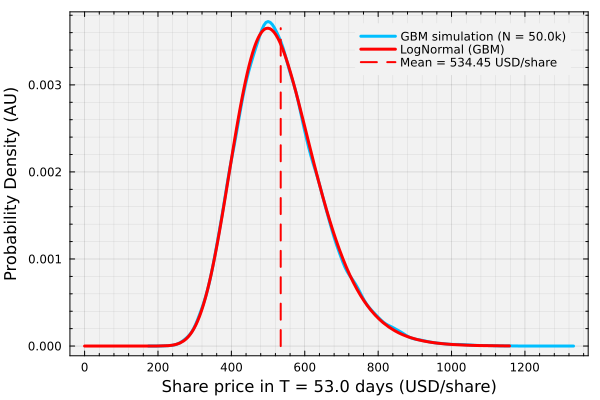

In [16]:
let

    # initialize: a dashed vertical line at the mean of d_gbm, from zero to the peak density -
    LX = ones(100) .* mean(d_gbm); # x: the mean, repeated (USD/share)
    LY = range(0, stop = maximum(pdf.(d_gbm, range(quantile(d_gbm,0.01), stop=quantile(d_gbm,0.99), length=100))), length = 100) |> collect; # y: zero to the peak

    # plot: the density of the simulated samples (blue) against the log-normal density (red) -
    density(endpoint_samples, lw=3, c=:deepskyblue1, label="GBM simulation (N = $(length(endpoint_samples)/1000)k)")
    plot!(d_gbm, lw=3, label="LogNormal (GBM)", c=:red,
        bg="gray95", background_color_outside="white", framestyle = :box, fg_legend = :transparent, xminorticks=true, xminorgrid = true, yminorgrid = true)
    plot!(LX, LY, lw=2, ls=:dash, c=:red, label="Mean = $(round(mean(d_gbm),digits=2)) USD/share")

    # labels -
    xlabel!("Share price in T = $(DTE) days (USD/share)", fontsize=18)
    ylabel!("Probability Density (AU)", fontsize=18)
end

### Alternative: Future share price projection using implied volatility
Alternatively, we could use the __implied volatility__ to estimate the expected share price move over the time to expiration $T$ (years).
Suppose we construct a [Normal distribution](https://juliastats.org/Distributions.jl/stable/univariate/#Distributions.Normal) $\mathcal{N}(\mu_{IV},\sigma_{IV})$ whose mean $\mu_{IV} = S_{0}\exp(g_{y}T)$ is the share price grown at the risk-free rate, or just $\mu_{IV}\approx{S}_{0}$ for short duration contracts, and whose standard deviation $\sigma_{IV}$ is:
$$
\sigma_{IV} = S_{0}\cdot\text{IV}\cdot\sqrt{T}
$$
where IV is the at-the-money implied volatility (decimal). We use the [Normal type exported by the Distributions.jl package](https://juliastats.org/Distributions.jl/stable/univariate/#Distributions.Normal). This is only an approximate model of the future share price; it has a couple of issues: 
> __Watch out!__ This model assumes a [Normal distribution](https://juliastats.org/Distributions.jl/stable/univariate/#Distributions.Normal), which is problematic because it can emit negative share prices. One way to fix this issue is to use a [Truncated Normal distribution](https://juliastats.org/Distributions.jl/stable/truncate/#Truncated-Distributions) instead.

However, despite the potential issues, this model is __widely__ used to generate quick estimates of future share price ranges using the forward-looking implied volatility. Let's save the Normal IV distribution $\mathcal{N}(\mu_{IV},\sigma_{IV})$ in the `d_IV::Normal` variable:

In [17]:
d_IV = let

    # initialize -
    ATM_IV = metadata["atm_IV"] |> x-> parse(Float64, x); # at-the-money implied volatility on the quote date (decimal)

    # build the Normal approximation: mean Sₒ grown at gᵧ, standard deviation Sₒ⋅IV⋅√T -
    d = Normal(Sₒ*exp(gᵧ*T), Sₒ*ATM_IV*sqrt(T));

    # return -
    d
end

Normal{Float64}(μ=534.4545050434095, σ=113.71114807827765)

`Unhide` the code block below to see how we plotted the `d_gbm::LogNormal` and `d_IV::Normal` future share price densities at expiration.  

> __What do we see?__ The log-normal GBM share price distribution (blue line) is right-skewed and cannot admit negative share prices. However, the Normal IV distribution (red line) is symmetric around its mean, the share price grown at the risk-free rate, and can admit negative share prices, albeit with a small probability.

How do the two distributions compare?

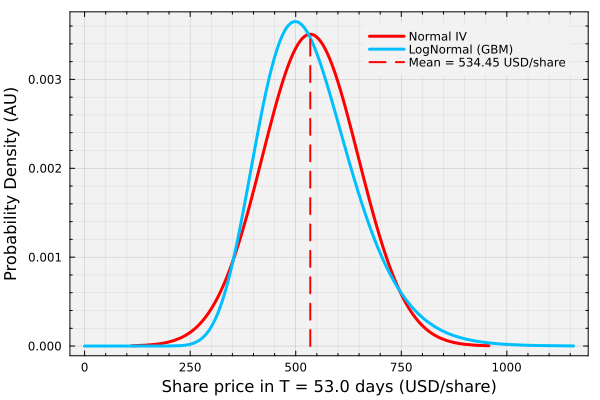

In [18]:
let

    # initialize: a dashed vertical line at the mean of d_IV, from zero to the peak density -
    LX = ones(100) .* mean(d_IV); # x: the mean, repeated (USD/share)
    LY = range(0, stop = maximum(pdf.(d_IV, range(quantile(d_IV,0.01), stop=quantile(d_IV,0.99), length=100))), length = 100) |> collect; # y: zero to the peak

    # plot: the Normal IV density (red) against the log-normal GBM density (blue) -
    plot(d_IV, lw=3, label="Normal IV", c=:red,
        bg="gray95", background_color_outside="white", framestyle = :box, fg_legend = :transparent, xminorticks=true, minorgrid = true);
    plot!(d_gbm, lw=3, label="LogNormal (GBM)", c=:deepskyblue1)
    plot!(LX, LY, lw=2, ls=:dash, c=:red, label="Mean = $(round(mean(d_IV),digits=2)) USD/share")

    # labels -
    xlabel!("Share price in T = $(DTE) days (USD/share)", fontsize=18)
    ylabel!("Probability Density (AU)", fontsize=18)
end

### Probability of Profit (POP)
The POP for a long (short) strangle position is given by the probability that the future share price at expiration $S(T)$ is outside (inside) the breakeven points $S^{\ddagger}_{-}$ and $S^{\ddagger}_{+}$. Let's look at the two cases:

> __Probability of Profit (POP) for Long Strangle__ 
> 
> The POP for a long strangle position is the probability that the future share price at expiration $S(T)$ is either greater than the upper breakeven point $S^{\ddagger}_{+}$ or less than the lower breakeven point $S^{\ddagger}_{-}$:
> $$
\begin{align*}
\text{POP} &= \mathbb{P}(S(T) > S^{\ddagger}_{+}) + \mathbb{P}(S(T) < S^{\ddagger}_{-}) \\
& = 1 - \mathbb{P}(S^{\ddagger}_{-} \leq S(T) \leq S^{\ddagger}_{+}) \\
& = 1 - \left[F_{S}(S^{\ddagger}_{+}) - F_{S}(S^{\ddagger}_{-})\right]
\end{align*}
$$
> where $F_{S}(x)$ is the cumulative distribution function (CDF) of the future share price at expiration, i.e., $F_{S}(x) = \mathbb{P}(S(T) \leq x)$.

However, if we were trading a short strangle position, the POP would be given by:
> __Probability of Profit (POP) for Short Strangle__ 
> 
> The POP for a short strangle position is the probability that the future share price at expiration $S(T)$ is between the lower breakeven point $S^{\ddagger}_{-}$ and the upper breakeven point $S^{\ddagger}_{+}$:
> $$
\begin{align*}
\text{POP} &= \mathbb{P}(S^{\ddagger}_{-} < S(T) < S^{\ddagger}_{+}) \\
& = F_{S}(S^{\ddagger}_{+}) - F_{S}(S^{\ddagger}_{-})
\end{align*}
$$
> where $F_{S}(x)$ is the cumulative distribution function (CDF) of the future share price at expiration, i.e., $F_{S}(x) = \mathbb{P}(S(T) \leq x)$.

### Probability of Exercise (POE) and Our Belief
Each leg has its own probability of exercise. The put is exercised if $S(T)<K_{1}-0.01$ and the call if $S(T)>K_{2}+0.01$, so $\text{POE}_{p}=F_{S}(K_{1}-0.01)$ and $\text{POE}_{c}=1-F_{S}(K_{2}+0.01)$.

So far, we used the risk-neutral probabilities $\mathbb{Q}$, the probabilities inside the market price. Our belief $\mathbb{P}$ uses the SAGBM parameters instead: geometric Brownian motion with drift $\hat{\mu}=\hat{\mu}_{g}+\hat{\sigma}^{2}/2$ and volatility $\hat{\sigma}$, where $\hat{\mu}_{g}$ (the `drift` column) and $\hat{\sigma}$ (the `volatility` column) are the AMD estimates we loaded earlier. Let's compute the POP of our position and each leg's POE for five distributions of the share price at expiration:
* __Our belief $\mathbb{P}$:__ log-normal, with drift $\hat{\mu}$ and volatility $\hat{\sigma}$.
* __Risk-neutral $\mathbb{Q}$:__ log-normal, with drift $g_{y}$ and the at-the-money implied volatility, the distribution `d_gbm` above.
* __Two mixed cases:__ the historical drift $\hat{\mu}$ with the implied volatility, and the risk-free rate $g_{y}$ with the historical volatility $\hat{\sigma}$. Each changes one input of $\mathbb{Q}$, so we can see which input moves the probabilities.
* __Normal IV:__ the quick approximation `d_IV` above, close to $\mathbb{Q}$ but not log-normal.

So what do we get?

In [19]:
share_price_distributions = let

    # initialize: the five share price distributions at expiration -
    S₊ = breakeven_array[1]; # upper breakeven S‡₊ (USD/share)
    S₋ = breakeven_array[2]; # lower breakeven S‡₋ (USD/share)
    amd = only(eachrow(filter(:ticker => ==("AMD"), parameters_df))); # AMD's SAGBM estimates
    μ̂_g = amd.drift; # mean growth rate (1/yr)
    σ̂ = amd.volatility; # historical volatility (1/sqrt(yr))
    μ̂ = μ̂_g + σ̂^2/2; # GBM drift of our belief ℙ (1/yr)
    cases = [ # (label, distribution of S(T)) for each row of the table
        ("our belief ℙ", LogNormal(log(Sₒ) + (μ̂ - σ̂^2/2)*T, σ̂*sqrt(T))),
        ("historical drift, implied volatility", LogNormal(log(Sₒ) + (μ̂ - model.σ^2/2)*T, model.σ*sqrt(T))),
        ("risk-neutral ℚ", d_gbm),
        ("risk-free drift, historical volatility", LogNormal(log(Sₒ) + (gᵧ - σ̂^2/2)*T, σ̂*sqrt(T))),
        ("Normal IV (approximates ℚ)", d_IV)
    ];

    # the POP of our position, and each leg's POE -
    df = DataFrame(case = String[], POP = Float64[], POE_put = Float64[], POE_call = Float64[]); # one row per distribution
    for (label, d) ∈ cases
        inside = cdf(d, S₊) - cdf(d, S₋); # probability that S(T) finishes between the breakevens
        POP = (θ == -1) ? inside : 1 - inside; # a short position profits inside, a long position outside
        push!(df, (label, POP, cdf(d, K₁ - 0.01), 1 - cdf(d, K₂ + 0.01))); # put POE at K₁ - 0.01, call POE at K₂ + 0.01
    end
    # show the results -
    pretty_table(df; column_labels = ["distribution of S(T)", "POP ($(θ == -1 ? "short" : "long") $(position))", "POE put", "POE call"],
        alignment = [:l, :r, :r, :r], formatters = [fmt__printf("%.4f", [2, 3, 4])],
        table_format = TextTableFormat(borders = text_table_borders__compact),
        fit_table_in_display_horizontally = false);
    println("our belief ℙ: μ̂_g = $(round(μ̂_g, digits = 4)), σ̂ = $(round(σ̂, digits = 4)), μ̂ = $(round(μ̂, digits = 4)) (1/yr)");
    println("risk-neutral ℚ: gᵧ = $(round(gᵧ, digits = 4)) (1/yr), ATM IV = $(model.σ)");

    # checks: the ℚ row is d_gbm, and every probability is between 0 and 1 -
    @assert isapprox(df.POE_put[3], cdf(d_gbm, K₁ - 0.01); atol = 1e-12) "the ℚ row does not match d_gbm"
    @assert all(0 .≤ Matrix(df[:, 2:4]) .≤ 1) "a probability is outside [0, 1]"

    cases; # return the (label, distribution) pairs
end;

 ---------------------------------------- ---------------------- --------- ----------
  distribution of S(T)                     POP (short strangle)   POE put   POE call 
 ---------------------------------------- ---------------------- --------- ----------
  our belief ℙ                                           0.7384    0.1512     0.2776
  historical drift, implied volatility                   0.6655    0.2004     0.2984
  risk-neutral ℚ                                         0.6714    0.3108     0.1906
  risk-free drift, historical volatility                 0.7534    0.2674     0.1585
  Normal IV (approximates ℚ)                             0.6811    0.2854     0.2004
 ---------------------------------------- ---------------------- --------- ----------
our belief ℙ: μ̂_g = 0.4397, σ̂ = 0.4743, μ̂ = 0.5521 (1/yr)
risk-neutral ℚ: gᵧ = 0.0413 (1/yr), ATM IV = 0.5617


> __What do we see?__
>
> * __The POP:__ Our belief $\mathbb{P}$ gives the short strangle a higher POP than $\mathbb{Q}$. The two mixed rows show why: the lower historical volatility alone raises the POP, and the larger historical drift alone lowers it. Here the volatility wins.
> * __The POE:__ The rows with the historical drift $\hat{\mu}$ shift the share price up. Compared with $\mathbb{Q}$, they make the call more likely, and the put less likely, to be exercised.
> * __The Normal IV approximation:__ It gives nearly the same POP as $\mathbb{Q}$, but it tilts the POE toward the call. A Normal distribution is symmetric about its mean, while the log-normal distribution puts its median below its mean.

`Unhide` the code block below to see how we plotted the cumulative distribution function $F_{S}(x)$ of each distribution in the table. The POP of the short strangle is the rise of a curve between the breakevens $S^{\ddagger}_{-}$ and $S^{\ddagger}_{+}$, the put's POE is the height of a curve at $K_{1}$, and the call's POE is one minus the height at $K_{2}$. The dashed lines read the heights of $\mathbb{P}$ and $\mathbb{Q}$ across to the probability axis.

> __What do we see?__ At the strikes $K_{1}$ and $K_{2}$ (purple lines), the two curves with the historical drift $\hat{\mu}$ (navy and orange lines) sit to the right of $\mathbb{Q}$ (blue line), so they are lower at both strikes: the put is less likely, and the call more likely, to be exercised than under $\mathbb{Q}$. The two curves with the historical volatility $\hat{\sigma}$ (navy and gray lines) are steeper between the breakevens (green lines), so they rise more there and give the short strangle a higher POP.

How do the cumulative distributions compare?

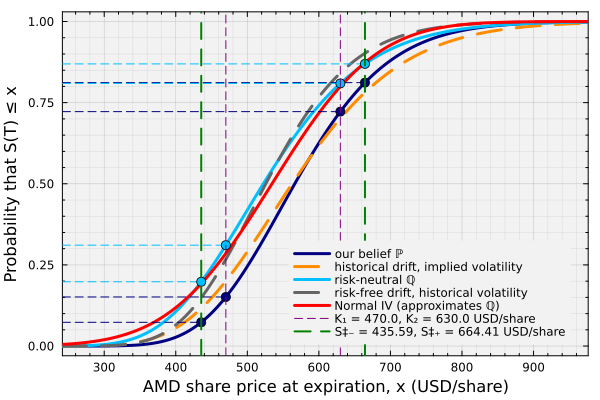

In [20]:
let

    # initialize: the share prices at expiration to plot -
    x = range(minimum(quantile(d, 0.005) for (_, d) ∈ share_price_distributions),
        stop = maximum(quantile(d, 0.995) for (_, d) ∈ share_price_distributions), length = 500) |> collect; # share price at expiration (USD/share)
    colors = [:navy, :darkorange, :deepskyblue1, :gray40, :red]; # same order as the rows of the table
    styles = [:solid, :dash, :solid, :dash, :solid]; # the two mixed cases are dashed

    # plot: the cumulative distribution F_S(x) of each row of the table -
    p = plot(bg="gray95", background_color_outside="white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, legend = :bottomright, legendfontsize = 8);
    for ((label, d), c, s) ∈ zip(share_price_distributions, colors, styles)
        plot!(p, x, cdf.(d, x), lw = 3, c = c, ls = s, label = label);
    end

    # read the heights of ℙ and ℚ at the vertical lines across to the probability axis, in each curve's color -
    for (label, d) ∈ share_price_distributions
        c = Dict("our belief ℙ" => :navy, "risk-neutral ℚ" => :deepskyblue1); # read-off colors match the curves
        haskey(c, label) || continue; # read off ℙ and ℚ only
        for v ∈ (K₁, K₂, breakeven_array[2], breakeven_array[1]) # share prices marked by the vertical lines (USD/share)
            plot!(p, [x[1], v], [cdf(d, v), cdf(d, v)], lw = 1, c = c[label], ls = :dash, label = "");
            scatter!(p, [v], [cdf(d, v)], ms = 5, c = c[label], msc = :black, msw = 1, label = ""); # where the line meets the curve, outlined
        end
    end
    xlims!(p, (x[1], x[end])); # start the plot at x[1], so the horizontal lines reach the axis

    # mark the strikes and the breakevens -
    vline!(p, [K₁, K₂], lw = 1, c = :purple, ls = :dash, label = "K₁ = $(K₁), K₂ = $(K₂) USD/share");
    vline!(p, [breakeven_array[2], breakeven_array[1]], lw = 2, c = :green, ls = :dash,
        label = "S‡₋ = $(round(breakeven_array[2], digits = 2)), S‡₊ = $(round(breakeven_array[1], digits = 2)) USD/share");

    # labels -
    xlabel!(p, "AMD share price at expiration, x (USD/share)", fontsize=18);
    ylabel!(p, "Probability that S(T) ≤ x", fontsize=18);
    p # return
end

___

## Task 3: Did we make money on the strangle?
In this task, we close our short strangle after AMD's earnings release and compute the profit or loss.

> __Earnings Release:__ [AMD reports its third-quarter 2026 results](https://ir.amd.com/news-events/press-releases/detail/1300/amd-to-report-fiscal-third-quarter-2026-financial-results) on `2026-11-03` after market close, after we priced the contracts on `2026-10-26`. Earnings releases can move the share price sharply in either direction. A short strangle profits if the share price stays between the breakevens, and a long strangle if it moves outside them.

The release comes weeks before expiration, so the breakevens alone cannot tell us whether we made money. Both legs still carry extrinsic value, and closing a short strangle means buying both legs back at their premiums on that day, $\mathcal{P}^{\prime}_{p}$ and $\mathcal{P}^{\prime}_{c}$. If we close $\tau$ years after we opened, the profit per share is:
$$
\hat{P}_{\mathcal{C}}(\tau) = \theta\cdot\Bigl[(\mathcal{P}^{\prime}_{p}+\mathcal{P}^{\prime}_{c})-\mathcal{D}_{\tau,0}(g_{y})\cdot(\mathcal{P}_{p}+\mathcal{P}_{c})\Bigr]
$$
where $\mathcal{D}_{\tau,0}(g_{y})=e^{g_{y}\tau}$. For our short strangle ($\theta=-1$), this is the premiums we collected when we sold the put and the call, grown to the closing day, minus the cost to buy both legs back.

Until the release, `post_release_ticker` is `missing` and the cells below print a pending message. After the release, download the AMD chain for the same expiration, save it as a new dataset, set `post_release_ticker` to its name, and rerun this task.

In [21]:
post_release_ticker = missing; # name of the AMD chain saved after the 2026-11-03 release (TODO: set it, for example "amd-2026-post")

What is our profit or loss if we close the strangle after the release?

In [22]:
ismissing(post_release_ticker) ? println("Pending: set post_release_ticker after the 2026-11-03 earnings release and rerun this task.") : let

    # initialize: the chain after the release -
    post = MyOptionsChainDataSet(ticker = post_release_ticker); # the chain and its metadata after the release
    chain = post.data; # DataFrame: one row per contract
    put_rows = filter([:Strike,:Type] => (x,y) -> (x == K₁ && y == "Put"), chain); # the K₁ put after the release
    call_rows = filter([:Strike,:Type] => (x,y) -> (x == K₂ && y == "Call"), chain); # the K₂ call after the release

    # the share price, and the time we held the position -
    S_post = post.metadata["underlying_share_price_mid"] |> x-> parse(Float64, x); # share price after the release (USD/share)
    days_held = (Date(post.metadata["purchase_date"]) - Date(metadata["purchase_date"])).value; # days from opening to closing
    τ = days_held*Δt; # time from opening to closing (years)
    𝒟_τ = exp(gᵧ*τ); # accumulation factor from opening to closing (dimensionless)

    # premiums: when we opened, and when we close -
    opened = put_option_model.premium + call_option_model.premium; # 𝒫_p + 𝒫_c (USD/share)
    P′_p = put_rows[1,:Mid]; # put premium after the release (USD/share)
    P′_c = call_rows[1,:Mid]; # call premium after the release (USD/share)
    profit_per_share = θ*((P′_p + P′_c) - 𝒟_τ*opened); # buy back (short) or sell (long) both legs (USD/share)

    # show the results -
    df = DataFrame(
        quantity = ["share price after the release", "days held", "premiums when opened, 𝒫_p + 𝒫_c",
            "premiums when closed, 𝒫′_p + 𝒫′_c", "profit or loss per share", "profit or loss, one $(position) (100 shares)"],
        value = [S_post, days_held, opened, P′_p + P′_c, profit_per_share, 100*profit_per_share],
        units = ["USD/share", "days", "USD/share", "USD/share", "USD/share", "USD"]);
    pretty_table(df; column_labels = ["quantity", "value", "units"], alignment = [:l, :r, :l],
        formatters = [fmt__printf("%.2f", [2])], fit_table_in_display_horizontally = false,
        table_format = TextTableFormat(borders = text_table_borders__compact));
    println("Breakevens at expiration: S‡₋ = $(round(breakeven_array[2], digits = 2)) and S‡₊ = $(round(breakeven_array[1], digits = 2)) USD/share");

    # checks: a chain from the close after the release, same expiration, one put at K₁ and one call at K₂ -
    @assert Date(post.metadata["purchase_date"]) ≥ Date(2026, 11, 4) "the post-release chain must be from 2026-11-04 or later (the release is after the close on 2026-11-03)"
    @assert post.metadata["expiration_date"] == metadata["expiration_date"] "the post-release chain must have the same expiration"
    @assert nrow(put_rows) == 1 && nrow(call_rows) == 1 "expected exactly one put at K₁ = $(K₁) and one call at K₂ = $(K₂)"
end

Pending: set post_release_ticker after the 2026-11-03 earnings release and rerun this task.


___

## Summary
In this example, we sold a strangle on AMD before its earnings release, computed its profit at expiration and its breakevens, and computed its probability of profit and each leg's probability of exercise under our belief and under the risk-neutral probabilities.

> __Key Takeaways:__
>
> * __Strangles have two breakeven points:__ We computed the profit at expiration of the short strangle as the credit grown to expiration minus the payoffs of both legs. It breaks even at the put strike minus, and the call strike plus, the premiums grown to expiration, and the short strangle profits only when the share price finishes between these two points. Setting $K_{1}=K_{2}$ gives the straddle.
> * __The probability of profit depends on whose probabilities we use:__ We computed the POP of the short strangle and each leg's POE from log-normal share prices under our belief $\mathbb{P}$ and under the risk-neutral probabilities $\mathbb{Q}$. Changing one input at a time showed that the lower historical volatility raised the POP under $\mathbb{P}$, while the larger historical drift made the call more likely, and the put less likely, to be exercised than under $\mathbb{Q}$.
> * __Closing early costs the extrinsic value left in the legs:__ We wrote the profit from closing after the earnings release as the credit grown to that day minus the cost to buy both legs back. Before expiration, those premiums still include extrinsic value, so the profit depends on the premiums when we close, not only on where the share price is relative to the breakevens.

Selling a strangle collects less credit than selling a straddle near the share price, but it keeps that credit over a wider range of share prices.
___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team. 

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success. Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___